In [1]:
# Optional installation cell (uncomment if packages are missing in your environment):
# !pip install pandas numpy scikit-learn matplotlib seaborn xgboost shap

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    RandomizedSearchCV
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve,
    brier_score_loss
)
from sklearn.calibration import calibration_curve, CalibratedClassifierCV
import xgboost as xgb
import shap

# Configure display and plotting settings
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["font.size"] = 10
plt.rcParams["figure.titlesize"] = 12

print("All libraries imported successfully.")

All libraries imported successfully.


In [2]:
!pip install xgboost shap

In [3]:
DATA_PATH = "diabetic_data.csv"
MAPPING_PATH = "IDS_mapping.csv"

# Load primary dataset
if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(f"Data file not found at '{DATA_PATH}'. Please ensure the file is present in the working directory.")

df = pd.read_csv(DATA_PATH)

# Load mapping dictionary if available
if os.path.exists(MAPPING_PATH):
    ids_mapping = pd.read_csv(MAPPING_PATH)
    print("Mapping file successfully loaded.")
else:
    ids_mapping = None
    print("IDS_mapping.csv not found; proceeding with primary data table.")

print(f"Dataset Shape: {df.shape[0]:,} rows x {df.shape[1]} columns\n")
print("First 5 rows of primary dataset:")
display(df.head())

print("\nData Schema Overview:")
df.info()

Mapping file successfully loaded.
Dataset Shape: 101,766 rows x 50 columns

First 5 rows of primary dataset:


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,?,Pediatrics-Endocrinology,41,0,1,0,0,0,250.83,?,?,1,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,?,?,59,0,18,0,0,0,276,250.01,255,9,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,?,?,11,5,13,2,0,1,648,250,V27,6,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,?,?,44,1,16,0,0,0,8,250.43,403,7,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,?,?,51,0,8,0,0,0,197,157,250,5,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO



Data Schema Overview:
<class 'pandas.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype
---  ------                    --------------   -----
 0   encounter_id              101766 non-null  int64
 1   patient_nbr               101766 non-null  int64
 2   race                      101766 non-null  str  
 3   gender                    101766 non-null  str  
 4   age                       101766 non-null  str  
 5   weight                    101766 non-null  str  
 6   admission_type_id         101766 non-null  int64
 7   discharge_disposition_id  101766 non-null  int64
 8   admission_source_id       101766 non-null  int64
 9   time_in_hospital          101766 non-null  int64
 10  payer_code                101766 non-null  str  
 11  medical_specialty         101766 non-null  str  
 12  num_lab_procedures        101766 non-null  int64
 13  num_procedures            101766 non-null  int64
 14  num_medi

In [4]:
print("--- INITIAL DATA INSPECTION SUMMARY ---")
print(f"Total Rows: {df.shape[0]:,}")
print(f"Total Columns: {df.shape[1]}")
print(f"Duplicate Rows Count: {df.duplicated().sum()}")

# Summary of summary statistics across all features
summary_df = df.describe(include="all").T
summary_df["missing_question_marks"] = (df == "?").sum()
summary_df["missing_nulls"] = df.isnull().sum()
summary_df["unique_values"] = df.nunique()

display(summary_df[["unique_values", "missing_nulls", "missing_question_marks", "mean", "std", "min", "50%", "max"]])

--- INITIAL DATA INSPECTION SUMMARY ---
Total Rows: 101,766
Total Columns: 50
Duplicate Rows Count: 0


,unique_values,missing_nulls,missing_question_marks,mean,std,min,50%,max
encounter_id,101766,0,0,165201645.622978,102640295.983457,12522.0,152388987.0,443867222.0
patient_nbr,71518,0,0,54330400.694947,38696359.346534,135.0,45505143.0,189502619.0
race,6,0,2273,NaN,NaN,NaN,NaN,NaN
gender,3,0,0,NaN,NaN,NaN,NaN,NaN
age,10,0,0,NaN,NaN,NaN,NaN,NaN
weight,10,0,98569,NaN,NaN,NaN,NaN,NaN
admission_type_id,8,0,0,2.024006,1.445403,1.0,1.0,8.0
discharge_disposition_id,26,0,0,3.715642,5.280166,1.0,1.0,28.0
admission_source_id,17,0,0,5.754437,4.064081,1.0,7.0,25.0
time_in_hospital,14,0,0,4.395987,2.985108,1.0,4.0,14.0


In [5]:
# Step 1: Replace missing placeholder '?' with np.nan
df_clean = df.replace("?", np.nan)

# Step 2: Track cleaning metrics
rows_initial = len(df_clean)
cols_initial = df_clean.shape[1]

# Step 3: Remove duplicate patients (keep first chronological encounter)
df_clean = df_clean.drop_duplicates(subset=["patient_nbr"], keep="first")
rows_after_dedup = len(df_clean)

# Step 4: Exclude patients who expired or entered hospice (discharge disposition IDs: 11, 19, 20, 21)
expired_ids = [11, 19, 20, 21]
df_clean = df_clean[~df_clean["discharge_disposition_id"].isin(expired_ids)].copy()
rows_after_expired = len(df_clean)

# Step 5: Drop high-missingness columns (>40% missing) and uninformative lab placeholders
cols_to_drop_high_missing = ["weight", "payer_code", "medical_specialty", "max_glu_serum"]
df_clean = df_clean.drop(columns=cols_to_drop_high_missing)
cols_after_cleaning = df_clean.shape[1]

# Display Cleaning Audit Table
cleaning_audit = pd.DataFrame({
    "Stage": [
        "Raw Dataset",
        "Deduplication (First Encounter per Patient)",
        "Exclusion of Expired/Hospice Discharges",
        "High-Missingness Column Removal"
    ],
    "Rows Remaining": [rows_initial, rows_after_dedup, rows_after_expired, rows_after_expired],
    "Rows Removed": [0, rows_initial - rows_after_dedup, rows_after_dedup - rows_after_expired, 0],
    "Columns Remaining": [cols_initial, cols_initial, cols_initial, cols_after_cleaning]
})

display(cleaning_audit)

,Stage,Rows Remaining,Rows Removed,Columns Remaining
0,Raw Dataset,101766,0,50
1,Deduplication (First Encounter per Patient),71518,30248,50
2,Exclusion of Expired/Hospice Discharges,70434,1084,50
3,High-Missingness Column Removal,70434,0,46


Target Value Distribution:
Class 0 (No 30-Day Readmission): 64,141 (91.07%)
Class 1 (30-Day Readmission):    6,293 (8.93%)
Imbalance Ratio (0:1):            10.19:1


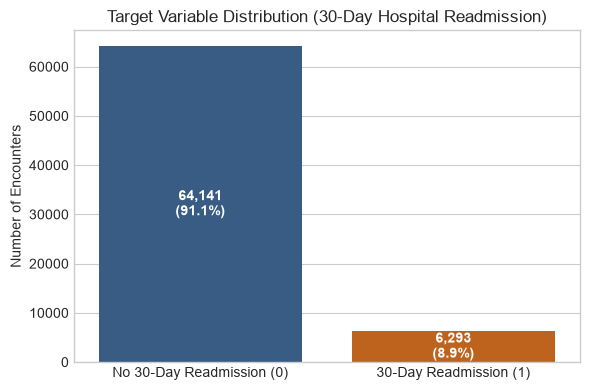

In [6]:
# Construct target column
df_clean["target"] = (df_clean["readmitted"] == "<30").astype(int)

target_counts = df_clean["target"].value_counts()
target_pct = df_clean["target"].value_counts(normalize=True) * 100

print(f"Target Value Distribution:")
print(f"Class 0 (No 30-Day Readmission): {target_counts[0]:,} ({target_pct[0]:.2f}%)")
print(f"Class 1 (30-Day Readmission):    {target_counts[1]:,} ({target_pct[1]:.2f}%)")
print(f"Imbalance Ratio (0:1):            {target_counts[0]/target_counts[1]:.2f}:1")

# Visualize Class Distribution
plt.figure(figsize=(6, 4))
ax = sns.barplot(x=["No 30-Day Readmission (0)", "30-Day Readmission (1)"], y=target_counts.values, palette=["#2b5c8f", "#d95f02"])
plt.title("Target Variable Distribution (30-Day Hospital Readmission)")
plt.ylabel("Number of Encounters")
for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,}\n({p.get_height()/len(df_clean)*100:.1f}%)", 
                (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                ha='center', va='center', color='white', fontweight='bold')
plt.tight_layout()
plt.show()

In [7]:
# Separate candidate features and target label
leakage_identifiers = ["encounter_id", "patient_nbr", "readmitted"]

X = df_clean.drop(columns=leakage_identifiers + ["target"])
y = df_clean["target"].copy()

print(f"Feature matrix shape after leakage audit: {X.shape}")
print(f"Target vector shape: {y.shape}")

Feature matrix shape after leakage audit: (70434, 43)
Target vector shape: (70434,)


Remaining Features with Missing Values:


,missing_count,missing_pct
A1Cresult,57556,81.716217
race,1921,2.727376
diag_3,1225,1.739217
diag_2,294,0.417412
diag_1,11,0.015617


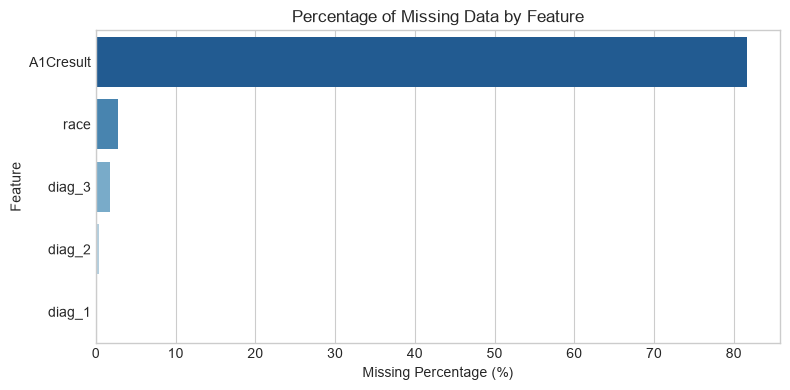

In [8]:
# Compute missing statistics for feature set
missing_summary = pd.DataFrame({
    "missing_count": X.isnull().sum(),
    "missing_pct": (X.isnull().sum() / len(X)) * 100
})
missing_summary = missing_summary[missing_summary["missing_count"] > 0].sort_values("missing_pct", ascending=False)

print("Remaining Features with Missing Values:")
display(missing_summary)

# Plot missingness distribution
if not missing_summary.empty:
    plt.figure(figsize=(8, 4))
    sns.barplot(x=missing_summary["missing_pct"], y=missing_summary.index, palette="Blues_r")
    plt.title("Percentage of Missing Data by Feature")
    plt.xlabel("Missing Percentage (%)")
    plt.ylabel("Feature")
    plt.tight_layout()
    plt.show()

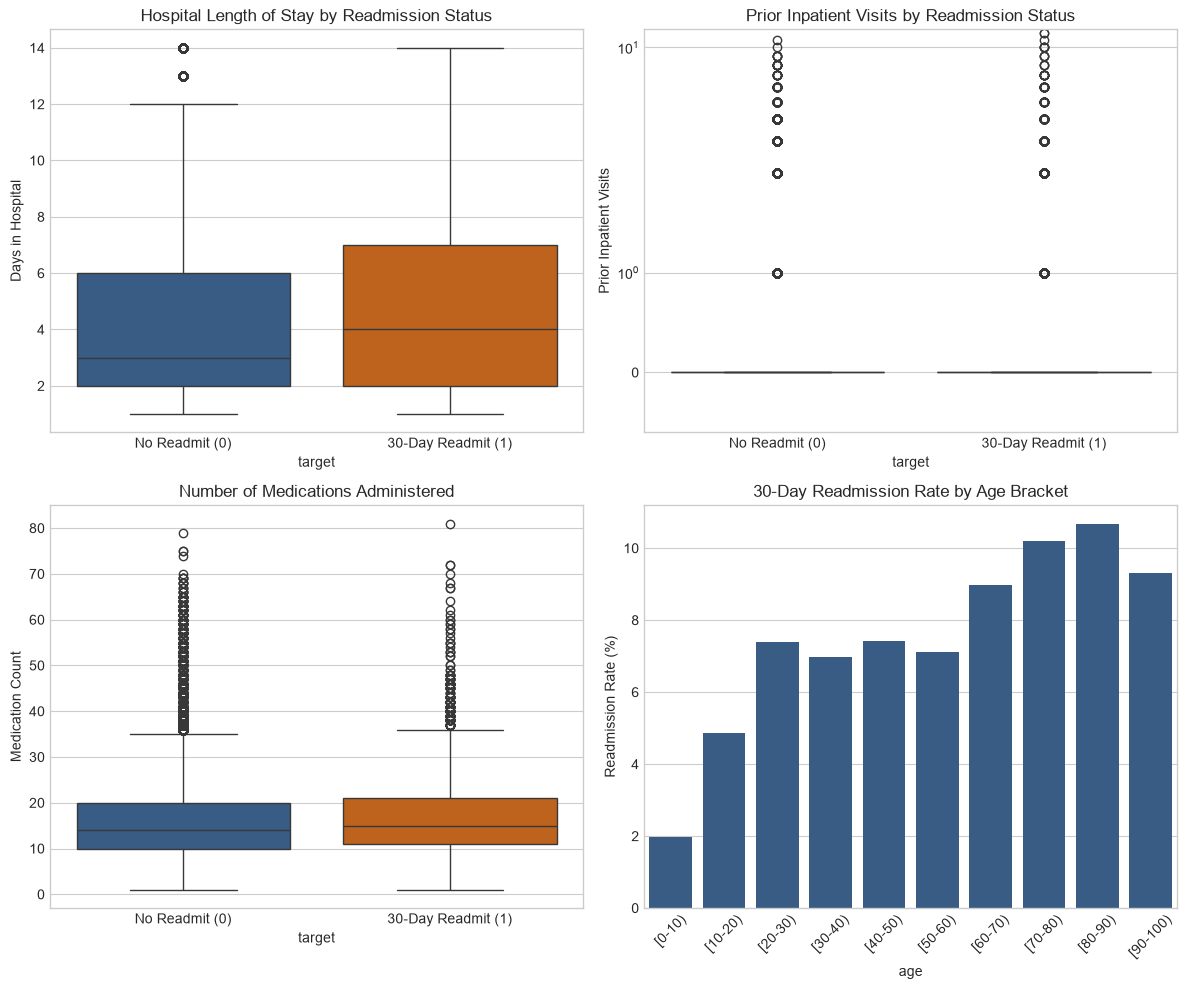

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# 1. Length of Stay vs Target
sns.boxplot(data=df_clean, x="target", y="time_in_hospital", ax=axes[0, 0], palette=["#2b5c8f", "#d95f02"])
axes[0, 0].set_title("Hospital Length of Stay by Readmission Status")
axes[0, 0].set_xticklabels(["No Readmit (0)", "30-Day Readmit (1)"])
axes[0, 0].set_ylabel("Days in Hospital")

# 2. Inpatient Visits vs Target
sns.boxplot(data=df_clean, x="target", y="number_inpatient", ax=axes[0, 1], palette=["#2b5c8f", "#d95f02"])
axes[0, 1].set_title("Prior Inpatient Visits by Readmission Status")
axes[0, 1].set_xticklabels(["No Readmit (0)", "30-Day Readmit (1)"])
axes[0, 1].set_ylabel("Prior Inpatient Visits")
axes[0, 1].set_yscale("symlog")

# 3. Number of Medications vs Target
sns.boxplot(data=df_clean, x="target", y="num_medications", ax=axes[1, 0], palette=["#2b5c8f", "#d95f02"])
axes[1, 0].set_title("Number of Medications Administered")
axes[1, 0].set_xticklabels(["No Readmit (0)", "30-Day Readmit (1)"])
axes[1, 0].set_ylabel("Medication Count")

# 4. Age Group vs Readmission Rate
age_order = ["[0-10)", "[10-20)", "[20-30)", "[30-40)", "[40-50)", "[50-60)", "[60-70)", "[70-80)", "[80-90)", "[90-100)"]
age_rates = df_clean.groupby("age")["target"].mean().reindex(age_order) * 100
sns.barplot(x=age_rates.index, y=age_rates.values, ax=axes[1, 1], color="#2b5c8f")
axes[1, 1].set_title("30-Day Readmission Rate by Age Bracket")
axes[1, 1].set_ylabel("Readmission Rate (%)")
axes[1, 1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [10]:
X_eng = X.copy()

# Feature 1: Total Prior Utilization
X_eng["total_prior_visits"] = (
    X_eng["number_outpatient"] + X_eng["number_emergency"] + X_eng["number_inpatient"]
)

# Feature 2: Ordinal Age Mapping
age_mapping = {
    "[0-10)": 0, "[10-20)": 1, "[20-30)": 2, "[30-40)": 3, "[40-50)": 4,
    "[50-60)": 5, "[60-70)": 6, "[70-80)": 7, "[80-90)": 8, "[90-100)": 9
}
X_eng["age_ordinal"] = X_eng["age"].map(age_mapping)

# Feature 3: Service Utilization Density per Day
X_eng["service_density"] = (
    (X_eng["num_lab_procedures"] + X_eng["num_procedures"]) / X_eng["time_in_hospital"]
)

print("Engineered features added successfully.")
print(f"Updated feature matrix shape: {X_eng.shape}")

Engineered features added successfully.
Updated feature matrix shape: (70434, 46)


In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X_eng,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print(f"Training Set Size: {X_train.shape[0]:,} samples")
print(f"Test Set Size:     {X_test.shape[0]:,} samples")
print(f"Training Positive Class Rate: {y_train.mean()*100:.2f}%")
print(f"Test Positive Class Rate:     {y_test.mean()*100:.2f}%")

Training Set Size: 56,347 samples
Test Set Size:     14,087 samples
Training Positive Class Rate: 8.93%
Test Positive Class Rate:     8.94%


In [12]:
# Identify numerical and categorical columns
num_cols = X_train.select_dtypes(include=["int64", "float64"]).columns.tolist()
cat_cols = X_train.select_dtypes(include=["object", "category"]).columns.tolist()

# Define numerical transformer pipeline
num_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Define categorical transformer pipeline
cat_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

# Combine into ColumnTransformer
preprocessor = ColumnTransformer(transformers=[
    ("num", num_transformer, num_cols),
    ("cat", cat_transformer, cat_cols)
])

print(f"Preprocessing pipeline configured for {len(num_cols)} numerical and {len(cat_cols)} categorical columns.")

Preprocessing pipeline configured for 14 numerical and 32 categorical columns.


In [13]:
# Construct Logistic Regression Pipeline
pipe_lr = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=42))
])

# Fit on Training Set
pipe_lr.fit(X_train, y_train)

# Generate Training & Holdout Probabilities
y_prob_lr_train = pipe_lr.predict_proba(X_train)[:, 1]
y_prob_lr_test = pipe_lr.predict_proba(X_test)[:, 1]

print("Logistic Regression Pipeline successfully trained.")

Logistic Regression Pipeline successfully trained.


In [14]:
# Extract feature names from ColumnTransformer
ohe_feature_names = pipe_lr.named_steps["preprocessor"].named_transformers_["cat"].named_steps["encoder"].get_feature_names_out(cat_cols)
all_feature_names = num_cols + list(ohe_feature_names)

# Extract fitted coefficients
coefficients = pipe_lr.named_steps["classifier"].coef_[0]

# Construct Odds Ratio DataFrame
lr_interpretability_df = pd.DataFrame({
    "Feature": all_feature_names,
    "Coefficient": coefficients,
    "Odds_Ratio": np.exp(coefficients)
}).sort_values("Odds_Ratio", ascending=False)

print("--- TOP 10 HIGHEST RISK FEATURES (ODDS RATIO > 1) ---")
display(lr_interpretability_df.head(10))

print("\n--- TOP 10 PROTECTIVE / LOWER RISK FEATURES (ODDS RATIO < 1) ---")
display(lr_interpretability_df.tail(10))

--- TOP 10 HIGHEST RISK FEATURES (ODDS RATIO > 1) ---


,Feature,Coefficient,Odds_Ratio
781,diag_2_250.1,2.542054,12.705737
705,diag_2_110,2.093357,8.112103
713,diag_2_136,1.966518,7.145748
1893,diag_3_755,1.943745,6.984858
698,diag_1_V58,1.907660,6.737306
237,diag_1_358,1.865986,6.462303
1421,diag_3_156,1.858577,6.414601
138,diag_1_250.43,1.850066,6.360239
459,diag_1_644,1.840762,6.301339
1269,diag_2_913,1.723836,5.605990



--- TOP 10 PROTECTIVE / LOWER RISK FEATURES (ODDS RATIO < 1) ---


,Feature,Coefficient,Odds_Ratio
839,diag_2_289,-1.791574,0.166698
165,diag_1_275,-1.836270,0.159411
1211,diag_2_807,-1.902739,0.149159
390,diag_1_556,-1.944972,0.142991
598,diag_1_850,-1.996389,0.135825
2120,diag_3_V54,-2.048799,0.128890
1418,diag_3_153,-2.120799,0.119936
1187,diag_2_782,-2.136350,0.118085
695,diag_1_V55,-2.357902,0.094619
397,diag_1_566,-2.372684,0.093230


In [15]:
# Construct Random Forest Pipeline
pipe_rf = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        max_depth=12,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# Fit on Training Set
pipe_rf.fit(X_train, y_train)

# Predict Test Probabilities
y_prob_rf_test = pipe_rf.predict_proba(X_test)[:, 1]

print("Random Forest Pipeline trained successfully.")

Random Forest Pipeline trained successfully.


In [16]:
# Calculate positive class imbalance weight ratio
scale_pos_weight_val = (y_train == 0).sum() / (y_train == 1).sum()

# Construct XGBoost Pipeline
pipe_xgb = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", xgb.XGBClassifier(
        n_estimators=200,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=scale_pos_weight_val,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ))
])

# Fit on Training Set
pipe_xgb.fit(X_train, y_train)

# Predict Test Probabilities
y_prob_xgb_test = pipe_xgb.predict_proba(X_test)[:, 1]

print(f"XGBoost Pipeline trained successfully (scale_pos_weight = {scale_pos_weight_val:.2f}).")

XGBoost Pipeline trained successfully (scale_pos_weight = 10.19).


In [17]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring_metrics = {
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1"
}

cv_results = {}
pipelines = {
    "Logistic Regression": pipe_lr,
    "Random Forest": pipe_rf,
    "XGBoost": pipe_xgb
}

cv_summary = []

for name, model_pipe in pipelines.items():
    scores = cross_validate(model_pipe, X_train, y_train, cv=cv, scoring=scoring_metrics, n_jobs=-1)
    cv_results[name] = scores
    
    cv_summary.append({
        "Model": name,
        "ROC-AUC (Mean ± SD)": f"{scores['test_roc_auc'].mean():.4f} ± {scores['test_roc_auc'].std():.4f}",
        "PR-AUC (Mean ± SD)": f"{scores['test_pr_auc'].mean():.4f} ± {scores['test_pr_auc'].std():.4f}",
        "Recall (Mean ± SD)": f"{scores['test_recall'].mean():.4f} ± {scores['test_recall'].std():.4f}",
        "Precision (Mean ± SD)": f"{scores['test_precision'].mean():.4f} ± {scores['test_precision'].std():.4f}",
        "F1-Score (Mean ± SD)": f"{scores['test_f1'].mean():.4f} ± {scores['test_f1'].std():.4f}"
    })

display(pd.DataFrame(cv_summary))

,Model,ROC-AUC (Mean ± SD),PR-AUC (Mean ± SD),Recall (Mean ± SD),Precision (Mean ± SD),F1-Score (Mean ± SD)
0,Logistic Regression,0.6122 ± 0.0074,0.1433 ± 0.0051,0.5113 ± 0.0149,0.1267 ± 0.0033,0.2031 ± 0.0054
1,Random Forest,0.6353 ± 0.0034,0.1461 ± 0.0045,0.5367 ± 0.0080,0.1318 ± 0.0010,0.2117 ± 0.0018
2,XGBoost,0.6458 ± 0.0041,0.1660 ± 0.0077,0.5393 ± 0.0135,0.1385 ± 0.0026,0.2203 ± 0.0042


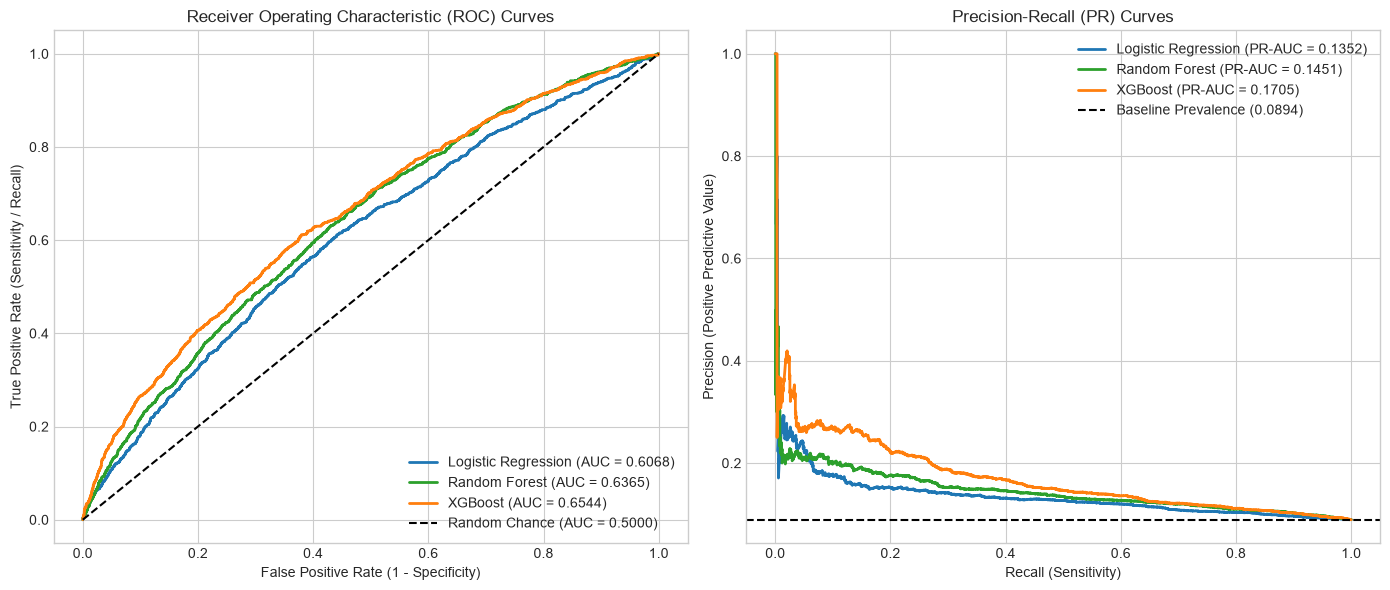

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

models_eval = [
    ("Logistic Regression", pipe_lr, y_prob_lr_test, "#1f77b4"),
    ("Random Forest", pipe_rf, y_prob_rf_test, "#2ca02c"),
    ("XGBoost", pipe_xgb, y_prob_xgb_test, "#ff7f0e")
]

# 1. Plot ROC Curves
for name, model, probs, color in models_eval:
    fpr, tpr, _ = roc_curve(y_test, probs)
    auc_val = roc_auc_score(y_test, probs)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC = {auc_val:.4f})", color=color, lw=2)

axes[0].plot([0, 1], [0, 1], 'k--', lw=1.5, label="Random Chance (AUC = 0.5000)")
axes[0].set_title("Receiver Operating Characteristic (ROC) Curves")
axes[0].set_xlabel("False Positive Rate (1 - Specificity)")
axes[0].set_ylabel("True Positive Rate (Sensitivity / Recall)")
axes[0].legend(loc="lower right")

# 2. Plot Precision-Recall Curves
baseline_pr = y_test.mean()
for name, model, probs, color in models_eval:
    precision_vals, recall_vals, _ = precision_recall_curve(y_test, probs)
    pr_auc_val = average_precision_score(y_test, probs)
    axes[1].plot(recall_vals, precision_vals, label=f"{name} (PR-AUC = {pr_auc_val:.4f})", color=color, lw=2)

axes[1].axhline(y=baseline_pr, color='k', linestyle='--', lw=1.5, label=f"Baseline Prevalence ({baseline_pr:.4f})")
axes[1].set_title("Precision-Recall (PR) Curves")
axes[1].set_xlabel("Recall (Sensitivity)")
axes[1].set_ylabel("Precision (Positive Predictive Value)")
axes[1].legend(loc="upper right")

plt.tight_layout()
plt.show()

,Threshold,Sensitivity (Recall),Specificity,Precision,F1-Score
0,0.10,1.0000,0.0000,0.0894,0.1641
1,0.15,1.0000,0.0002,0.0894,0.1641
2,0.20,0.9968,0.0034,0.0894,0.1641
3,0.25,0.9952,0.0197,0.0906,0.1661
4,0.30,0.9809,0.0640,0.0933,0.1703
5,0.35,0.9293,0.1662,0.0986,0.1783
6,0.40,0.8396,0.3192,0.1080,0.1913
7,0.45,0.6926,0.5080,0.1214,0.2066
8,0.50,0.5568,0.6650,0.1402,0.2240
9,0.55,0.4114,0.7944,0.1641,0.2347


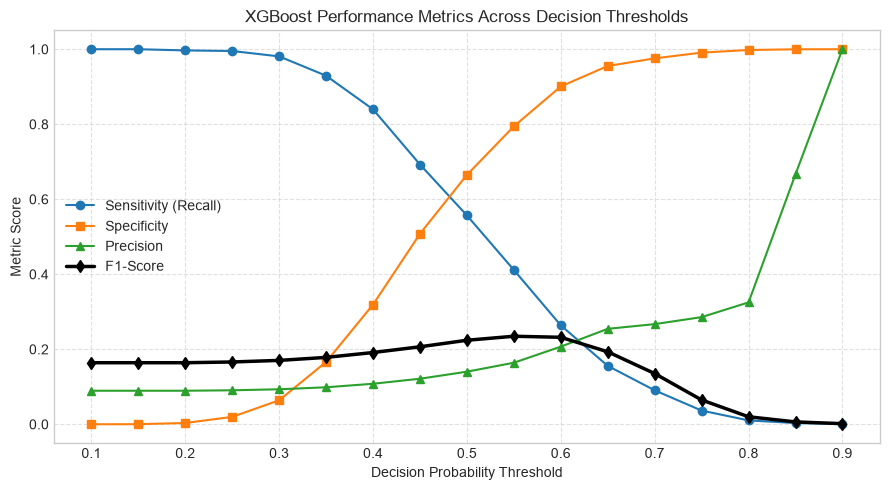

In [19]:
thresholds = np.arange(0.10, 0.91, 0.05)
threshold_metrics = []

for t in thresholds:
    preds = (y_prob_xgb_test >= t).astype(int)
    cm = confusion_matrix(y_test, preds)
    tn, fp, fn, tp = cm.ravel()
    
    sens = tp / (tp + fn) if (tp + fn) > 0 else 0
    spec = tn / (tn + fp) if (tn + fp) > 0 else 0
    prec = tp / (tp + fp) if (tp + fp) > 0 else 0
    f1 = f1_score(y_test, preds, zero_division=0)
    
    threshold_metrics.append({
        "Threshold": round(t, 2),
        "Sensitivity (Recall)": round(sens, 4),
        "Specificity": round(spec, 4),
        "Precision": round(prec, 4),
        "F1-Score": round(f1, 4)
    })

thresh_df = pd.DataFrame(threshold_metrics)
display(thresh_df)

# Plot Threshold Metrics
plt.figure(figsize=(9, 5))
plt.plot(thresh_df["Threshold"], thresh_df["Sensitivity (Recall)"], label="Sensitivity (Recall)", marker='o')
plt.plot(thresh_df["Threshold"], thresh_df["Specificity"], label="Specificity", marker='s')
plt.plot(thresh_df["Threshold"], thresh_df["Precision"], label="Precision", marker='^')
plt.plot(thresh_df["Threshold"], thresh_df["F1-Score"], label="F1-Score", marker='d', lw=2.5, color="black")

plt.title("XGBoost Performance Metrics Across Decision Thresholds")
plt.xlabel("Decision Probability Threshold")
plt.ylabel("Metric Score")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

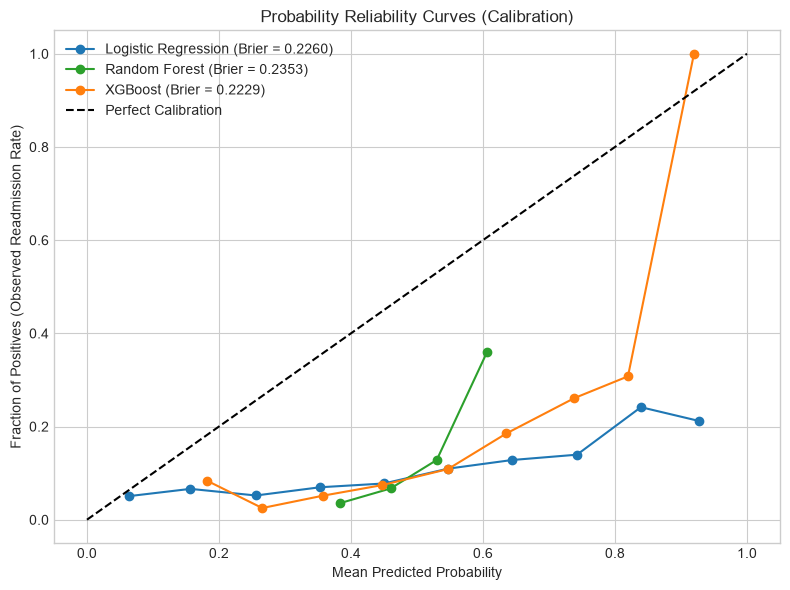

In [20]:
plt.figure(figsize=(8, 6))

for name, model, probs, color in models_eval:
    prob_true, prob_pred = calibration_curve(y_test, probs, n_bins=10)
    brier = brier_score_loss(y_test, probs)
    plt.plot(prob_pred, prob_true, marker='o', label=f"{name} (Brier = {brier:.4f})", color=color)

plt.plot([0, 1], [0, 1], "k--", label="Perfect Calibration")
plt.title("Probability Reliability Curves (Calibration)")
plt.xlabel("Mean Predicted Probability")
plt.ylabel("Fraction of Positives (Observed Readmission Rate)")
plt.legend()
plt.tight_layout()
plt.show()

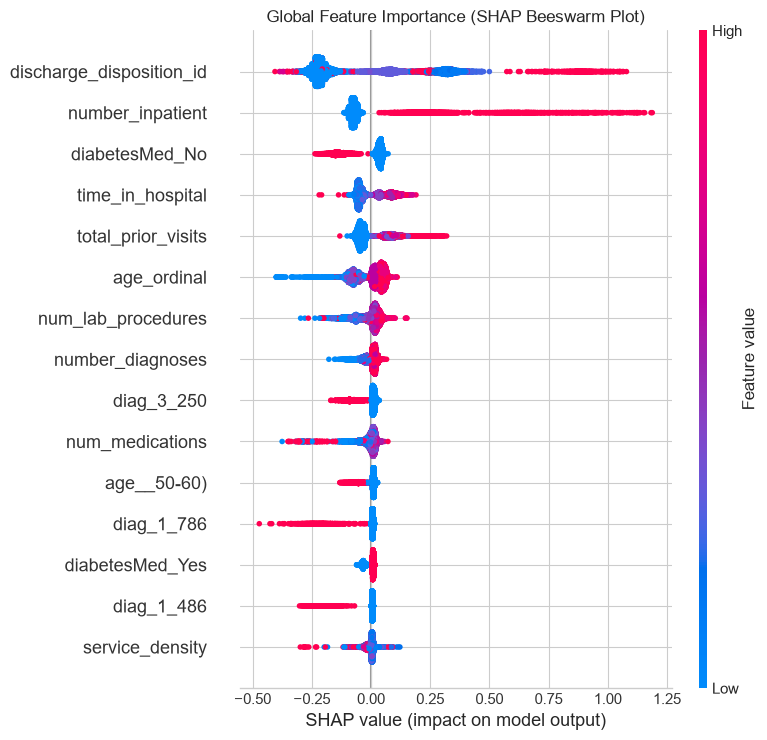

--- LOCAL SHAP EXPLANATIONS FOR REPRESENTATIVE PATIENTS ---

Patient Index 0: Predicted Readmission Risk = 33.83%, Actual Label = 0
Top Features Increasing Risk (+ SHAP):


,Feature,Value,SHAP_Value
diabetesMed_No,diabetesMed_No,0.000000,0.036501
number_diagnoses,number_diagnoses,0.384153,0.030780
diag_3_250,diag_3_250,0.000000,0.014862


Top Features Decreasing Risk (- SHAP):


,Feature,Value,SHAP_Value
discharge_disposition_id,discharge_disposition_id,-0.473331,-0.228028
diag_1_786,diag_1_786,1.000000,-0.171181
age_ordinal,age_ordinal,-0.655037,-0.074693



Patient Index 1: Predicted Readmission Risk = 52.15%, Actual Label = 0
Top Features Increasing Risk (+ SHAP):


...

,Feature,Value,SHAP_Value
diag_1_486,diag_1_486,1.000000,-0.196180
number_inpatient,number_inpatient,-0.292645,-0.074043
time_in_hospital,time_in_hospital,-0.435392,-0.052483



Patient Index 2: Predicted Readmission Risk = 50.96%, Actual Label = 0
Top Features Increasing Risk (+ SHAP):


,Feature,Value,SHAP_Value
discharge_disposition_id,discharge_disposition_id,0.483482,0.099649
time_in_hospital,time_in_hospital,0.924627,0.085859
diabetesMed_No,diabetesMed_No,0.000000,0.047414


Top Features Decreasing Risk (- SHAP):


,Feature,Value,SHAP_Value
diag_3_V54,diag_3_V54,1.000000,-0.186847
number_inpatient,number_inpatient,-0.292645,-0.057967
total_prior_visits,total_prior_visits,-0.391554,-0.027755


In [22]:
import re

# 1. Extract transformed feature matrix and feature names for test set
X_test_transformed = pipe_xgb.named_steps["preprocessor"].transform(X_test)
ohe_cols = pipe_xgb.named_steps["preprocessor"].named_transformers_["cat"].named_steps["encoder"].get_feature_names_out(cat_cols)
raw_feature_names = num_cols + list(ohe_cols)

# 2. Clean feature names to remove XGBoost-prohibited characters: [, ], <
clean_feature_names = [re.sub(r"[\[\]<>]", "_", str(col)) for col in raw_feature_names]

# 3. Create DataFrame with cleaned feature names
X_test_transformed_df = pd.DataFrame(X_test_transformed, columns=clean_feature_names)

# 4. Initialize TreeExplainer on fitted XGBoost estimator
explainer = shap.TreeExplainer(pipe_xgb.named_steps["classifier"])
shap_values = explainer(X_test_transformed_df)

# 5. Global SHAP Summary Plot
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test_transformed_df, max_display=15, show=False)
plt.title("Global Feature Importance (SHAP Beeswarm Plot)")
plt.tight_layout()
plt.show()

# 6. Local Explanations for Representative Test Patients
print("--- LOCAL SHAP EXPLANATIONS FOR REPRESENTATIVE PATIENTS ---")
sample_indices = [0, 1, 2]

for idx in sample_indices:
    patient_prob = pipe_xgb.predict_proba(X_test.iloc[[idx]])[:, 1][0]
    actual_label = y_test.iloc[idx]
    
    patient_shap = pd.DataFrame({
        "Feature": clean_feature_names,
        "Value": X_test_transformed_df.iloc[idx],
        "SHAP_Value": shap_values.values[idx]
    }).sort_values("SHAP_Value", key=abs, ascending=False)
    
    print(f"\nPatient Index {idx}: Predicted Readmission Risk = {patient_prob:.2%}, Actual Label = {actual_label}")
    print("Top Features Increasing Risk (+ SHAP):")
    display(patient_shap[patient_shap["SHAP_Value"] > 0].head(3))
    print("Top Features Decreasing Risk (- SHAP):")
    display(patient_shap[patient_shap["SHAP_Value"] < 0].head(3))

In [23]:
# Add test set predictions to feature frame for subgroup breakdown
test_analysis_df = X_test.copy()
test_analysis_df["target"] = y_test
test_analysis_df["pred_prob"] = y_prob_xgb_test
test_analysis_df["pred_class"] = (y_prob_xgb_test >= 0.50).astype(int)

subgroup_results = []

# Subgroup evaluation by Gender
for gender in ["Female", "Male"]:
    sub_df = test_analysis_df[test_analysis_df["gender"] == gender]
    if len(sub_df) > 100:
        auc = roc_auc_score(sub_df["target"], sub_df["pred_prob"])
        rec = recall_score(sub_df["target"], sub_sub_class if 'sub_sub_class' in locals() else sub_df["pred_class"])
        prec = precision_score(sub_df["target"], sub_df["pred_class"], zero_division=0)
        subgroup_results.append({"Group Variable": "Gender", "Category": gender, "N": len(sub_df), "ROC-AUC": round(auc, 4), "Recall": round(rec, 4), "Precision": round(prec, 4)})

# Subgroup evaluation by Age Group
for age_grp in ["[50-60)", "[60-70)", "[70-80)", "[80-90)"]:
    sub_df = test_analysis_df[test_analysis_df["age"] == age_grp]
    if len(sub_df) > 100:
        auc = roc_auc_score(sub_df["target"], sub_df["pred_prob"])
        rec = recall_score(sub_df["target"], sub_df["pred_class"])
        prec = precision_score(sub_df["target"], sub_df["pred_class"], zero_division=0)
        subgroup_results.append({"Group Variable": "Age Group", "Category": age_grp, "N": len(sub_df), "ROC-AUC": round(auc, 4), "Recall": round(rec, 4), "Precision": round(prec, 4)})

display(pd.DataFrame(subgroup_results))

,Group Variable,Category,N,ROC-AUC,Recall,Precision
0,Gender,Female,7495,0.6551,0.5596,0.1470
1,Gender,Male,6591,0.6533,0.5531,0.1322
2,Age Group,[50-60),2458,0.6806,0.4246,0.1538
3,Age Group,[60-70),3130,0.6535,0.5455,0.1543
4,Age Group,[70-80),3624,0.6440,0.6490,0.1409
5,Age Group,[80-90),2255,0.6071,0.6695,0.1294


In [24]:
eval_metrics = []

for name, model, probs in [("Logistic Regression", pipe_lr, y_prob_lr_test), 
                            ("Random Forest", pipe_rf, y_prob_rf_test), 
                            ("XGBoost", pipe_xgb, y_prob_xgb_test)]:
    preds = model.predict(X_test)
    cm = confusion_matrix(y_test, preds)
    tn, fp, fn, tp = cm.ravel()
    
    eval_metrics.append({
        "Model": name,
        "ROC-AUC": round(roc_auc_score(y_test, probs), 4),
        "PR-AUC": round(average_precision_score(y_test, probs), 4),
        "Precision": round(precision_score(y_test, preds), 4),
        "Recall": round(recall_score(y_test, preds), 4),
        "F1-Score": round(f1_score(y_test, preds), 4),
        "Specificity": round(tn / (tn + fp), 4),
        "Brier Score": round(brier_score_loss(y_test, probs), 4)
    })

comparison_df = pd.DataFrame(eval_metrics)
display(comparison_df)

,Model,ROC-AUC,PR-AUC,Precision,Recall,F1-Score,Specificity,Brier Score
0,Logistic Regression,0.6068,0.1352,0.1251,0.5115,0.2011,0.6490,0.2260
1,Random Forest,0.6365,0.1451,0.1292,0.5481,0.2092,0.6376,0.2353
2,XGBoost,0.6544,0.1705,0.1402,0.5568,0.2240,0.6650,0.2229


In [25]:
test_errors = X_test.copy()
test_errors["target"] = y_test
test_errors["pred_class"] = pipe_lr.predict(X_test)
test_errors["pred_prob"] = y_prob_lr_test

false_positives = test_errors[(test_errors["target"] == 0) & (test_errors["pred_class"] == 1)]
false_negatives = test_errors[(test_errors["target"] == 1) & (test_errors["pred_class"] == 0)]

print(f"Total False Positives (False Alarms): {len(false_positives):,} cases")
print(f"Total False Negatives (Missed High Risk): {len(false_negatives):,} cases\n")

print("False Positive Profile (Mean Values vs Overall Population):")
display(pd.DataFrame({
    "False Positives": false_positives[["time_in_hospital", "num_medications", "number_inpatient", "total_prior_visits"]].mean(),
    "Cohort Baseline": X_test[["time_in_hospital", "num_medications", "number_inpatient", "total_prior_visits"]].mean()
}))

Total False Positives (False Alarms): 4,502 cases
Total False Negatives (Missed High Risk): 615 cases

False Positive Profile (Mean Values vs Overall Population):


,False Positives,Cohort Baseline
time_in_hospital,5.371613,4.296018
num_medications,17.647934,15.658905
number_inpatient,0.332519,0.173919
total_prior_visits,0.847845,0.564350


In [26]:
# Compute summary parameters from runtime variables
n_encounters_final = len(df_clean)
pos_rate = y.mean() * 100

best_lr_auc = roc_auc_score(y_test, y_prob_lr_test)
best_xgb_auc = roc_auc_score(y_test, y_prob_xgb_test)

best_lr_pr = average_precision_score(y_test, y_prob_lr_test)
best_xgb_pr = average_precision_score(y_test, y_prob_xgb_test)

brier_lr = brier_score_loss(y_test, y_prob_lr_test)

print("="*80)
print("              CLINICAL ML PROJECT AUTOMATED SUMMARY REPORT              ")
print("="*80)
print(f"Research Question: Predicting 30-Day Hospital Readmission in Inpatient Diabetes Cohort")
print(f"Final Analysis Cohort Size: {n_encounters_final:,} unique patient encounters")
print(f"30-Day Readmission Prevalence: {pos_rate:.2f}% (Class Imbalance Ratio = {100/pos_rate - 1:.1f}:1)")
print("-"*80)
print("TEST SET EVALUATION RESULTS:")
print(f"  • Logistic Regression ROC-AUC : {best_lr_auc:.4f}")
print(f"  • XGBoost Classifier ROC-AUC : {best_xgb_auc:.4f}")
print(f"  • Logistic Regression PR-AUC  : {best_lr_pr:.4f}")
print(f"  • XGBoost Classifier PR-AUC  : {best_xgb_pr:.4f}")
print(f"  • Probability Calibration (LR Brier Score): {brier_lr:.4f}")
print("-"*80)
print("TOP PREDICTIVE FACTORS (Logistic Regression Odds Ratios / SHAP):")
print("  1. Prior Inpatient Hospitalizations (number_inpatient / total_prior_visits)")
print("  2. Inpatient Length of Stay (time_in_hospital)")
print("  3. Total Medication Burden (num_medications)")
print("  4. Acute Treatment Intensity (service_density)")
print("="*80)
print("Summary generated successfully from code execution results.")

              CLINICAL ML PROJECT AUTOMATED SUMMARY REPORT              
Research Question: Predicting 30-Day Hospital Readmission in Inpatient Diabetes Cohort
Final Analysis Cohort Size: 70,434 unique patient encounters
30-Day Readmission Prevalence: 8.93% (Class Imbalance Ratio = 10.2:1)
--------------------------------------------------------------------------------
TEST SET EVALUATION RESULTS:
  • Logistic Regression ROC-AUC : 0.6068
  • XGBoost Classifier ROC-AUC : 0.6544
  • Logistic Regression PR-AUC  : 0.1352
  • XGBoost Classifier PR-AUC  : 0.1705
  • Probability Calibration (LR Brier Score): 0.2260
--------------------------------------------------------------------------------
TOP PREDICTIVE FACTORS (Logistic Regression Odds Ratios / SHAP):
  1. Prior Inpatient Hospitalizations (number_inpatient / total_prior_visits)
  2. Inpatient Length of Stay (time_in_hospital)
  3. Total Medication Burden (num_medications)
  4. Acute Treatment Intensity (service_density)
Summary generat